# PAGA — HSC per-condition comparison

PAGA run independently on each condition subset (WT / mCh− / mCh+) so
inter-cluster connectivity reflects within-condition topology rather than
the pooled graph.

**Sections**
1. Load + condition map
2. Per-condition PAGA at a sweep of edge cutoffs
3. Conditions side-by-side at a single cutoff
4. PAGA overlaid on shared UMAP
5. Edge-weight comparison table

In [1]:
import scanpy as sc
import anndata as ad
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path

matplotlib.rcParams['figure.dpi'] = 120
sc.settings.verbosity = 1

H5AD      = Path('output/objects/hsc.h5ad')
OUT       = Path('output/objects/paga_conditions')
OUT.mkdir(parents=True, exist_ok=True)

CLUST_COL = 'sNN_pca.SCT_30_res.0.9'

# Map sample.name → short condition label
COND_MAP = {
    'HSC_WT_CD41+'      : 'WT',
    'HSC_Het_CD41+mCh-' : 'mCh-',
    'HSC_Het_CD41+mCh+' : 'mCh+',
}
COND_ORDER  = ['WT', 'mCh-', 'mCh+']
COND_COLORS = {'WT': '#1f78b4', 'mCh-': '#a6cee3', 'mCh+': '#e31a1c'}

## 1 · Load + assign condition

In [2]:
adata = sc.read_h5ad(H5AD)
adata.obs['condition'] = adata.obs['sample.name'].map(COND_MAP).astype('category')
adata.obs[CLUST_COL]   = adata.obs[CLUST_COL].astype(str).astype('category')

print(adata)
print()
print(adata.obs.groupby('condition').size().rename('n_cells'))

AnnData object with n_obs × n_vars = 50056 × 11057
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'cell.name', 'tube', 'sample.name', 'sample.name.long', 'compartment', 'nCount_HTO', 'nFeature_HTO', 'percent.mt', 'percent.rp', 'percent.hb', 'count_feat_ratio', 'percent.stress', 'S.Score', 'G2M.Score', 'Phase', 'dm2_max_prop', 'dm2_max_resid', 'dm2_class', 'pass_mt', 'pass_nFeature', 'pass_rp', 'pass_hb', 'pass_qc', 'pass_hto', 'scDblFinder.score', 'scDblFinder.class', 'pass_dbl', 'pass_cell', 'nCount_SCT', 'nFeature_SCT', 'sNN_pca.SCT_30_res.0.1', 'sNN_pca.SCT_30_res.0.3', 'sNN_pca.SCT_30_res.0.5', 'sNN_pca.SCT_30_res.0.7', 'sNN_pca.SCT_30_res.0.9', 'sNN_pca.SCT_30_res.1', 'sNN_pca.SCT_30_res.1.2', 'sNN_pca.SCT_30_res.1.3', 'sNN_pca.SCT_30_res.1.5', 'seurat_clusters', 'cytotrace2_score', 'cytotrace2_potency', 'cytotrace2_relative', 'condition'
    obsm: 'X_pca', 'X_umap'

condition
WT      16511
mCh+    15840
mCh-    17705
Name: n_cells, dtype: int64


## 2 · Build per-condition subsets + PAGA

Each subset gets its own kNN graph (same parameters as the full pipeline:
50 PCs, 30 neighbours).  Clusters that are absent in a condition are dropped
from that panel automatically.

In [3]:
def build_paga(adata_full, condition, clust_col, n_pcs=50, n_neighbors=30):
    """Subset to one condition, recompute neighbours, run PAGA."""
    sub = adata_full[adata_full.obs['condition'] == condition].copy()
    # Keep only clusters present in this condition
    sub.obs[clust_col] = sub.obs[clust_col].cat.remove_unused_categories()
    sc.pp.neighbors(sub, n_neighbors=n_neighbors, n_pcs=n_pcs,
                    use_rep='X_pca', random_state=42)
    sc.tl.paga(sub, groups=clust_col)
    print(f"  {condition}: {sub.n_obs:,} cells, "
          f"{sub.obs[clust_col].nunique()} clusters")
    return sub

subsets = {}
for cond in COND_ORDER:
    subsets[cond] = build_paga(adata, cond, CLUST_COL)

  WT: 16,511 cells, 21 clusters
  mCh-: 17,705 cells, 21 clusters
  mCh+: 15,840 cells, 21 clusters


In [ ]:
# Shared UMAP positions (from full dataset — same reference frame for all conditions)
full_cats  = adata.obs[CLUST_COL].cat.categories
shared_pos = np.array([
    adata.obsm['X_umap'][adata.obs[CLUST_COL] == c].mean(axis=0)
    for c in full_cats
])

# Per-condition UMAP positions (aligned to full_cats index)
cond_pos = {}
for cond, sub in subsets.items():
    cond_cats = sub.obs[CLUST_COL].cat.categories
    idx = [list(full_cats).index(c) for c in cond_cats if c in list(full_cats)]
    cond_pos[cond] = shared_pos[idx]

def _umap_colors(adata_obj, clust_col):
    cats    = list(adata_obj.obs[clust_col].cat.categories)
    palette = adata_obj.uns.get(f'{clust_col}_colors',
                ['#%02x%02x%02x' % tuple(int(c*255) for c in
                  __import__('matplotlib').cm.tab20(i/max(len(cats),1))[:3])
                 for i in range(len(cats))])
    cmap = {c: palette[i] for i, c in enumerate(cats)}
    return [cmap[c] for c in adata_obj.obs[clust_col]]

def paga_on_umap(full_adata, sub_adata, cond, ax, threshold, title, clust_col,
                 pos, scatter_size=0.8, scatter_alpha=0.2,
                 node_size_scale=1.5, edge_width_scale=0.5, fontsize=9):
    """Grey background (all cells) + condition cells highlighted + PAGA overlay."""
    umap = full_adata.obsm['X_umap']
    mask = full_adata.obs['condition'] == cond
    # Grey background
    ax.scatter(umap[~mask, 0], umap[~mask, 1],
               c='#dddddd', s=scatter_size, alpha=0.15, linewidths=0, rasterized=True)
    # Condition cells coloured by cluster
    cell_colors = _umap_colors(sub_adata, clust_col)
    ax.scatter(umap[mask, 0], umap[mask, 1],
               c=cell_colors, s=scatter_size, alpha=scatter_alpha,
               linewidths=0, rasterized=True)
    sc.pl.paga(sub_adata, threshold=threshold, pos=pos, ax=ax, show=False,
               title=title, frameon=False, fontsize=fontsize,
               node_size_scale=node_size_scale, edge_width_scale=edge_width_scale)
    ax.axis('off')

print('Shared UMAP positions computed for', len(full_cats), 'clusters')


## 3 · Per-condition PAGA across cutoffs

Rows = conditions, columns = edge cutoffs.

Saved: /project/output/paga_conditions/paga_conditions_cutoffs_sNN_pca.SCT_30_res.0.9.png


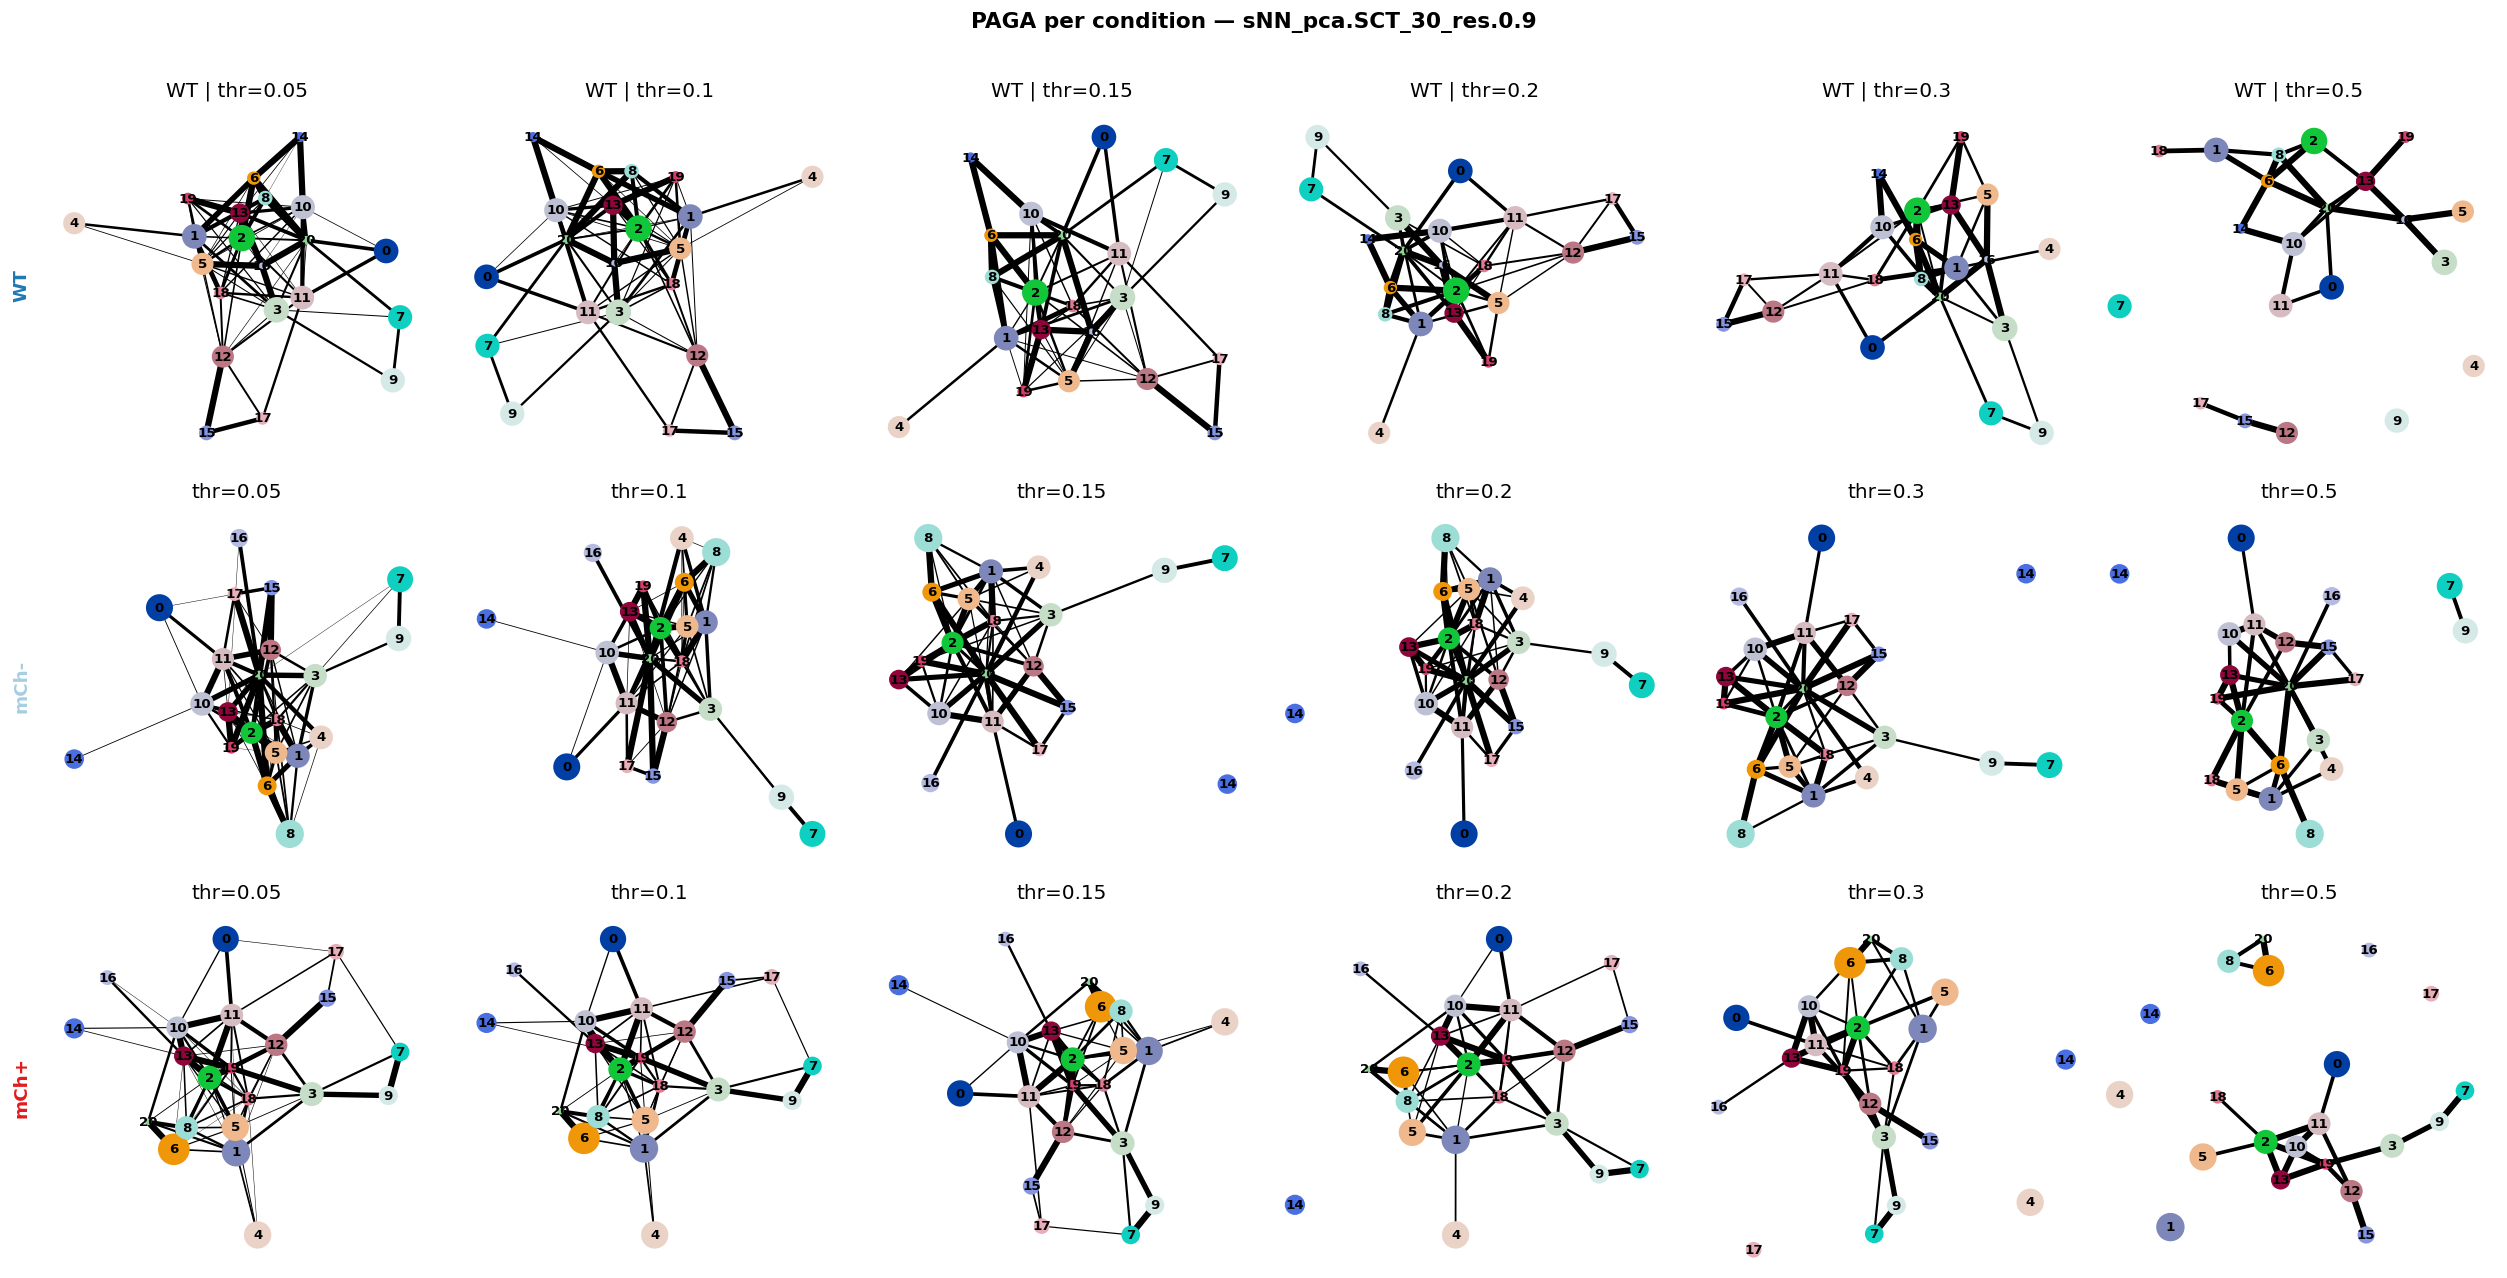

In [13]:
CUTOFFS = [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]

n_cond = len(COND_ORDER)
n_cut  = len(CUTOFFS)

fig, axes = plt.subplots(n_cond, n_cut, figsize=(n_cut * 3.5, n_cond * 3.5))
fig.suptitle(f'PAGA per condition — {CLUST_COL} (UMAP overlay)',
             fontsize=13, fontweight='bold', y=1.01)

for r, cond in enumerate(COND_ORDER):
    for c, threshold in enumerate(CUTOFFS):
        ax = axes[r, c]
        title = (f'thr={threshold}')
        paga_on_umap(adata, subsets[cond], cond, ax,
                     threshold=threshold, title=title,
                     clust_col=CLUST_COL, pos=cond_pos[cond],
                     scatter_size=0.6, scatter_alpha=0.25,
                     node_size_scale=1.0, edge_width_scale=1.5, fontsize=8)
        if c == 0:
            ax.set_ylabel(cond, fontsize=11, fontweight='bold',
                          color=COND_COLORS[cond], labelpad=6)

plt.tight_layout()
out = OUT / f'paga_conditions_cutoffs_{CLUST_COL}.png'
fig.savefig(out, dpi=150, bbox_inches='tight')
print(f'Saved: {out}')
plt.show()


## 4 · Side-by-side at a single cutoff

Cleaner panel for presentations — one fixed threshold.

Saved: /project/output/paga_conditions/paga_conditions_thr0.1_sNN_pca.SCT_30_res.0.9.png


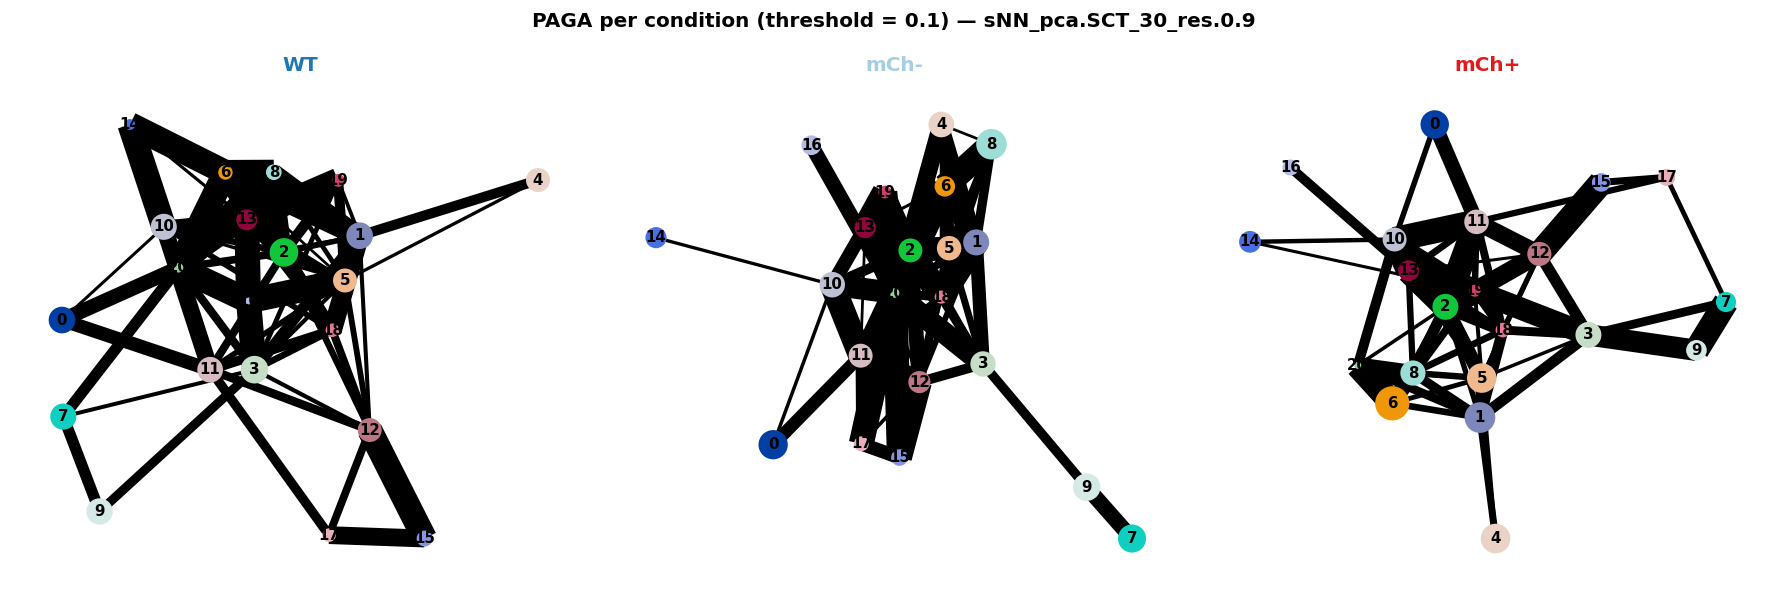

In [6]:
THRESHOLD = 0.10

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(f'PAGA per condition (threshold = {THRESHOLD}) — {CLUST_COL}',
             fontsize=12, fontweight='bold')

for ax, cond in zip(axes, COND_ORDER):
    paga_on_umap(adata, subsets[cond], cond, ax,
                 threshold=THRESHOLD, title=cond,
                 clust_col=CLUST_COL, pos=cond_pos[cond],
                 scatter_size=0.8, scatter_alpha=0.3,
                 node_size_scale=1.5, edge_width_scale=2.0, fontsize=9)
    ax.set_title(cond, fontsize=12, fontweight='bold', color=COND_COLORS[cond])

plt.tight_layout()
out = OUT / f'paga_conditions_thr{THRESHOLD}_{CLUST_COL}.png'
fig.savefig(out, dpi=150, bbox_inches='tight')
print(f'Saved: {out}')
plt.show()


## 5 · PAGA overlaid on shared UMAP

Nodes pinned to median UMAP coordinates of the **full** dataset so the
three panels share a common spatial reference.

Saved: /project/output/paga_conditions/paga_conditions_umap_sNN_pca.SCT_30_res.0.9.png


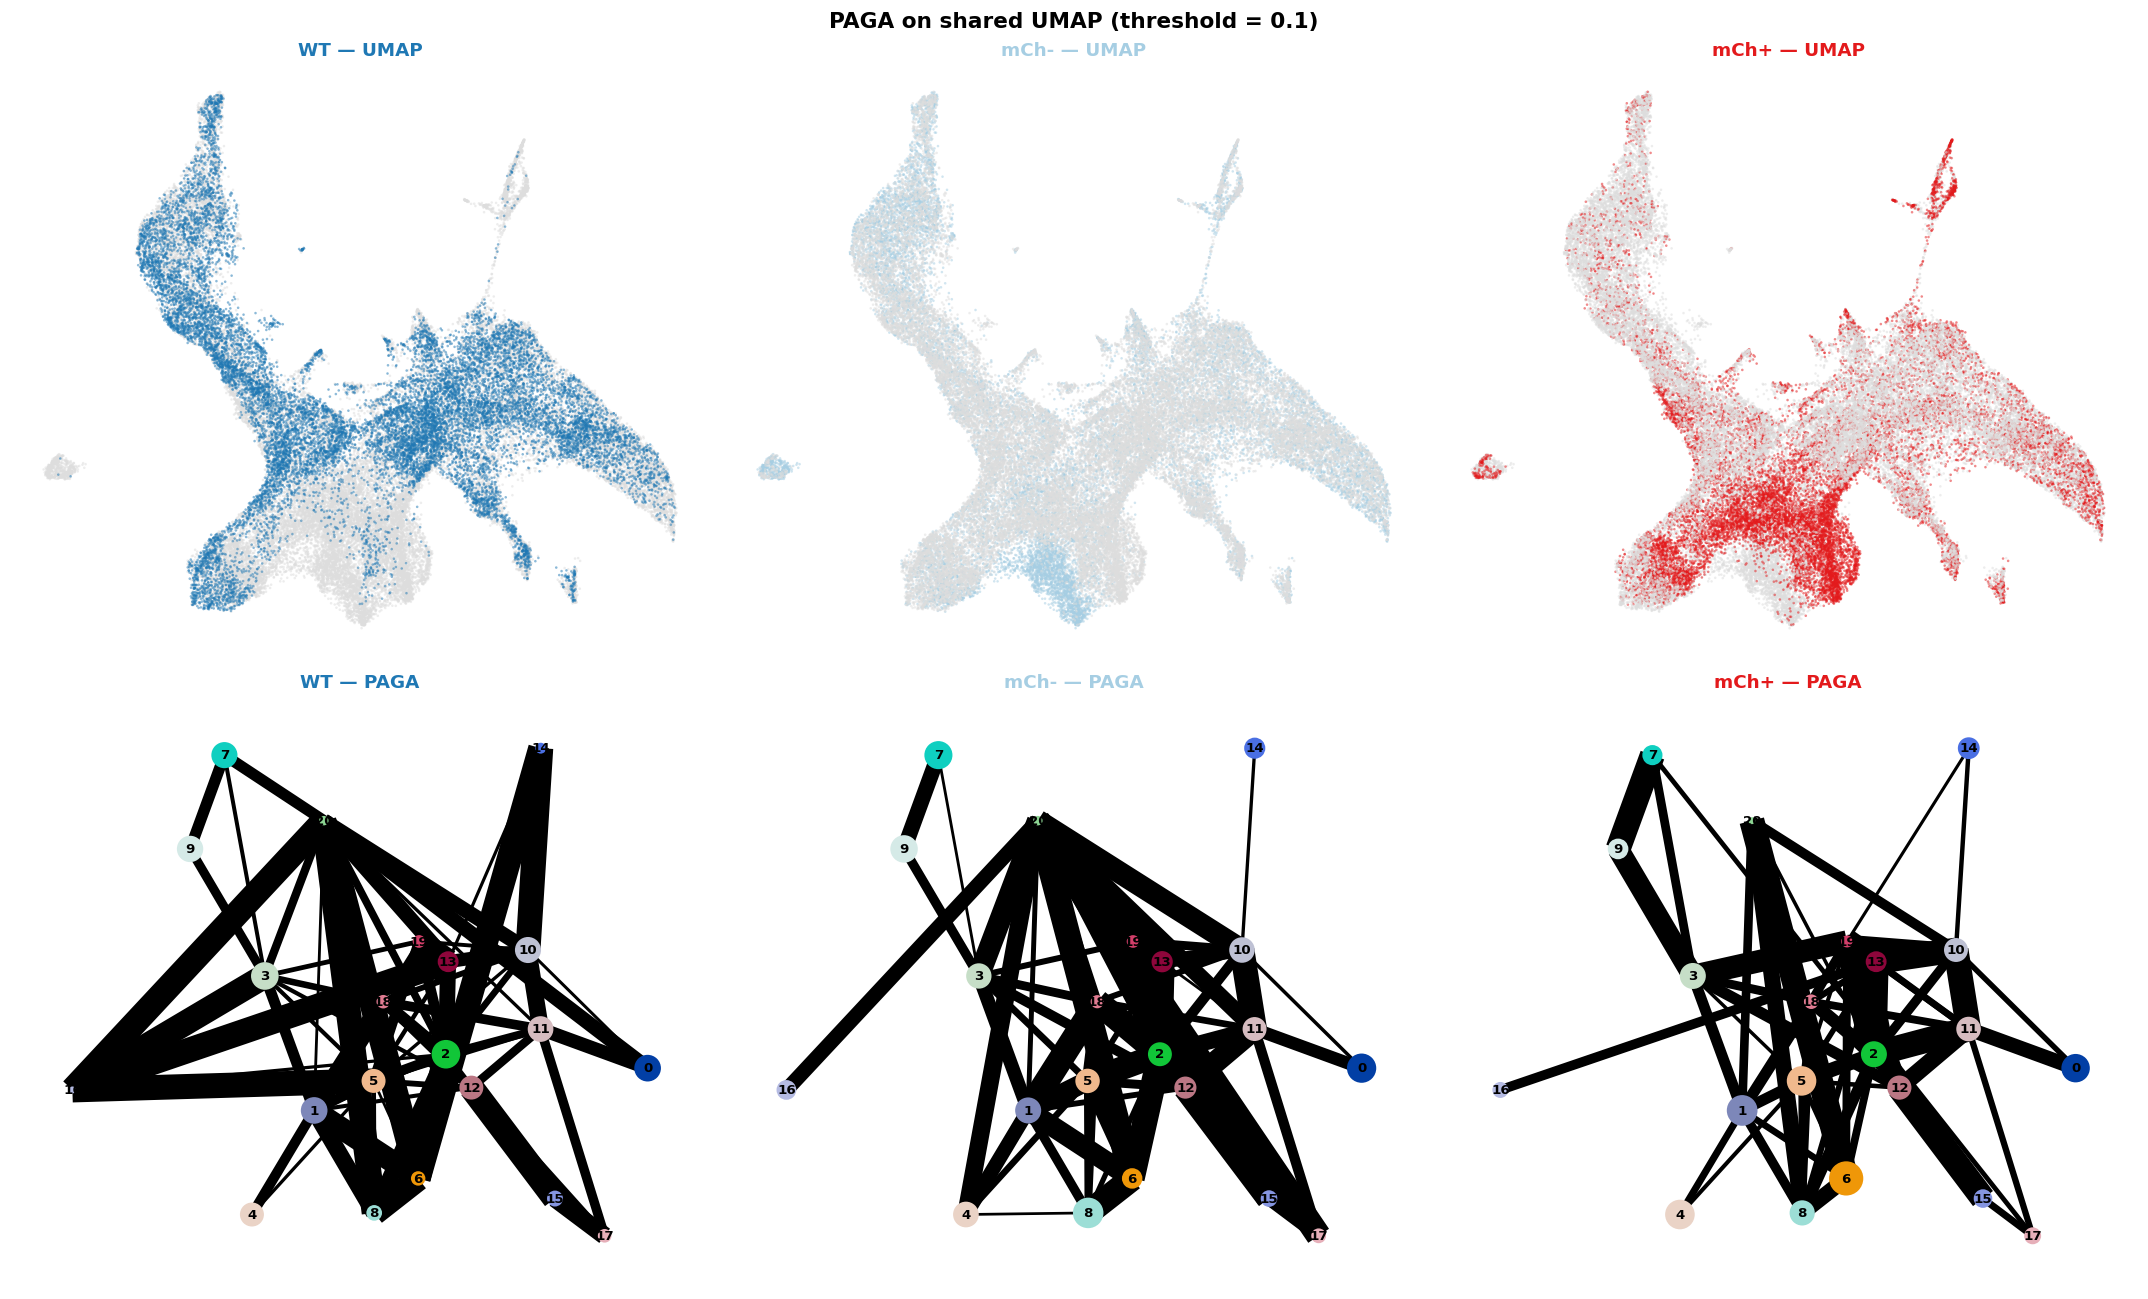

In [7]:
# Section 5 reuses the same paga_on_umap helper — panels already consistent.
# This section saves a 1×3 summary with all cells visible (no grey bg).
THRESHOLD_UMAP = 0.10

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(f'PAGA on shared UMAP (threshold = {THRESHOLD_UMAP})',
             fontsize=13, fontweight='bold')

for ax, cond in zip(axes, COND_ORDER):
    sub = subsets[cond]
    # All cells as background (cluster colours), PAGA on top
    cell_colors = _umap_colors(adata, CLUST_COL)
    ax.scatter(adata.obsm['X_umap'][:, 0], adata.obsm['X_umap'][:, 1],
               c=cell_colors, s=0.6, alpha=0.15, linewidths=0, rasterized=True)
    sc.pl.paga(sub, threshold=THRESHOLD_UMAP, pos=cond_pos[cond],
               ax=ax, show=False, title=cond, frameon=False, fontsize=9,
               node_size_scale=1.5, edge_width_scale=2.0)
    ax.set_title(cond, fontsize=12, fontweight='bold', color=COND_COLORS[cond])
    ax.axis('off')

plt.tight_layout()
out = OUT / f'paga_conditions_umap_{CLUST_COL}.png'
fig.savefig(out, dpi=150, bbox_inches='tight')
print(f'Saved: {out}')
plt.show()


## 6 · Edge-weight comparison table

All cluster pairs × all conditions.  Useful for spotting connections that
appear in one condition but not others.

In [10]:
def paga_edges(sub, cond):
    conn = sub.uns['paga']['connectivities']
    cats = sub.obs[CLUST_COL].cat.categories
    rows = []
    n = conn.shape[0]
    for i in range(n):
        for j in range(i + 1, n):
            w = float(conn[i, j])
            rows.append({'cluster_A': cats[i], 'cluster_B': cats[j],
                         'pair': f'{cats[i]}-{cats[j]}', 'weight': round(w, 4)})
    return pd.DataFrame(rows).assign(condition=cond)

all_edges = pd.concat([paga_edges(subsets[c], c) for c in COND_ORDER])

# Wide table: rows = cluster pairs, cols = conditions.
# Weights are raw PAGA connectivity scores (0–1) — no cutoff applied.
# The threshold parameter only affects what is drawn in the plots.
edge_wide = (
    all_edges
    .pivot_table(index='pair', columns='condition', values='weight', fill_value=0)
    [COND_ORDER]
    .reset_index()
)
edge_wide.columns.name = None   # remove pandas axis label ('condition') from display
edge_wide['max_weight'] = edge_wide[COND_ORDER].max(axis=1)
edge_wide = edge_wide.sort_values('max_weight', ascending=False).reset_index(drop=True)

out = OUT / f'paga_edge_comparison_{CLUST_COL}.csv'
edge_wide.to_csv(out, index=False)
print(f'Saved: {out}')
edge_wide.head(30)

Saved: /project/output/paga_conditions/paga_edge_comparison_sNN_pca.SCT_30_res.0.9.csv


,pair,WT,mCh-,mCh+,max_weight
0,20-8,1.0000,0.0000,0.6435,1.0000
1,6-8,1.0000,1.0000,0.6258,1.0000
2,18-2,0.4928,1.0000,0.5182,1.0000
3,13-16,1.0000,0.0696,0.3873,1.0000
4,10-14,1.0000,0.1326,0.1774,1.0000
5,10-11,0.6770,0.9927,1.0000,1.0000
6,11-2,0.3214,0.6601,1.0000,1.0000
7,1-18,0.7645,1.0000,0.4509,1.0000
8,2-6,1.0000,1.0000,0.3091,1.0000
9,13-2,0.6361,1.0000,1.0000,1.0000
